In [1]:
import numpy as np

In [2]:
T = 2
path_count = 75000
N = 100

mean_val = np.zeros(7)
sdev = np.zeros(7)
variances = np.zeros(7)
dts = np.zeros(7)

In [3]:
#iterate over 7 different N values
for outer in np.arange(7):
    #determine and store delta-t
    dt = T/N
    dts[outer] = dt
    
    #initialize Z and I
    Z0 = 0
    I0 = 0
    Z = Z0*np.ones(path_count)
    I = I0*np.ones(path_count)
    
    #vectorized timestep update for all simulations at once.
    for i in np.arange(N):
        #draw vector of normally distributed random values
        phi_t = np.random.randn(path_count)
        
        #scale appropriately
        dZ = np.sqrt(dt)*phi_t
        
        #update I accordingly
        I = I + dZ*dZ
        
    #store the outcomes
    path_results = I

    #compute the statistics of the distribution
    mean_val[outer] = np.mean(path_results)
    variances[outer] = np.var(path_results)
    N = N*2

In [4]:
print('dt\t\tmean\t\t\tvariance')
for outer in np.arange(7):
    print (str(dts[outer]) + ":   \t" + str(mean_val[outer]) + "\t" + str(variances[outer]))

dt		mean			variance
0.02:   	2.0013433416274564	0.0804532791231517
0.01:   	1.9984965258634637	0.04006383328835305
0.005:   	1.9997502126770672	0.020013395658252324
0.0025:   	2.0001527982981604	0.009966235968617444
0.00125:   	2.00035053326476	0.004965661484749215
0.000625:   	1.9999399013161512	0.0024804189902623178
0.0003125:   	2.0002692338541226	0.0012455823107236056


In [5]:
import matplotlib.pyplot as plt

Text(0,0.5,'Variance: var(I(T,dt))')

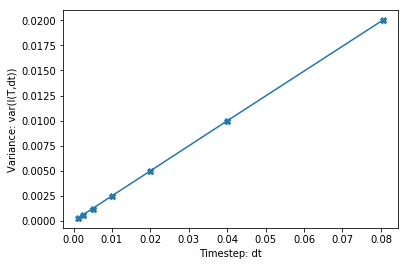

In [12]:
plt.plot(variances, dts,'X-')
plt.xlabel("Timestep: dt")
plt.ylabel("Variance: var(I(T,dt))")

(Fine if the axes are swapped, since the question wasn't totally clear, and it doesn't change the shape of the graph anyway.)

Our main observation from the plot is that as delta-t gets small (i.e., going from right to left)
, the variance is trending in essentially a straight line towards 0. Thus in the limit of dt -> 0, variance also goes to zero and thus the value of the sum is becoming deterministic. This is consistent with the section on Ito's Lemma where we said that dZ^2 = dt as dt->0.

It also makes sense that in the table, the mean value we get for I is about 1.5, since that's the input value of T. Since sum(dt)=T=2, and dZ^2=dt, then naturally we also get sum(dZ^2)=2 on average.